<a href="https://colab.research.google.com/github/piihutanoch/pet-breed-classifier/blob/main/notebooks/01b_eda_buildDS_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import json, re, hashlib, random
import pandas as pd

project_dir= Path("/content/drive/MyDrive/pet-breed-classifier")
artifacts_dir= project_dir / "artifacts_v2"      # NEW folder: v1 artifacts stay untouched
indie_dir= project_dir / "indie_raw"         # Indie photos live here (on Drive)
data_dir= Path("/content/data")             # Oxford + Stanford photos (local disk, fast)

artifacts_dir.mkdir(parents=True, exist_ok=True)
data_dir.mkdir(parents=True, exist_ok=True)

seed = 42
random.seed(seed)

MAX_PER_BREED = 250       # cap so merged breeds (Oxford + Stanford) don't get ~2x the photos
MIN_PER_BREED = 20        # a breed needs at least this many photos to be split 70/15/15

Mounted at /content/drive


In [3]:
# Oxford-IIIT Pet (same as Day 1)
!wget -q --show-progress https://s3.amazonaws.com/fast-ai-imageclas/oxford-iiit-pet.tgz -O /content/pets.tgz
!tar -xzf /content/pets.tgz -C /content/data

/content/pets.tgz   100%[===================>] 774.10M  62.6MB/s    in 12s     


In [4]:
# Stanford Dogs from Kaggle
import kagglehub
from pathlib import Path

kaggle_path = Path(kagglehub.dataset_download("jessicali9530/stanford-dogs-dataset"))

# find the folder that holds the 120 breed folders, wherever Kaggle put it
breeds_parent = next(kaggle_path.rglob("n02085620-Chihuahua")).parent

# link it to /content/data/Images so the rest of the notebook works unchanged
!rm -rf /content/data/Images
!ln -s "{breeds_parent}" /content/data/Images
!ls /content/data/Images | head -3
!ls /content/data/Images | wc -l

Using Colab cache for faster access to the 'stanford-dogs-dataset' dataset.
n02085620-Chihuahua
n02085782-Japanese_spaniel
n02085936-Maltese_dog
120


In [5]:
oxford_img_dir= data_dir/"oxford-iiit-pet"/"images"
stanford_img_dir= data_dir/"Images"

# These three roots are how every notebook finds the photos.
# manifest.csv stores only (source, path relative to its root), so it works in every new Colab session.
ROOTS = {"oxford": str(oxford_img_dir), "stanford": str(stanford_img_dir), "indie": str(indie_dir)}

for name, root in ROOTS.items():
    print(f"{name:9s} exists: {Path(root).exists()}  ->  {root}")

oxford    exists: True  ->  /content/data/oxford-iiit-pet/images
stanford  exists: True  ->  /content/data/Images
indie     exists: True  ->  /content/drive/MyDrive/pet-breed-classifier/indie_raw


### Step 2: List every photo with its breed

**Name clean-up.** Oxford writes `english_cocker_spaniel`, Stanford writes `cocker_spaniel`, and both
mean the same breed. `normalise()` turns any name into lowercase words joined by `_` so they can be compared.

**Merging.** 21 of Oxford's 25 dog breeds also exist in Stanford under a slightly different name.
`OXFORD_TO_STANFORD` says which is which, so e.g. Oxford *Japanese Chin* + Stanford *Japanese spaniel*
become **one** class. Without this, the model would be punished for confusing a breed with itself.

**Not merged on purpose:** Oxford *American Pit Bull Terrier* and Stanford *American Staffordshire terrier*
are close relatives but officially different breeds, so they stay separate.

In [6]:
def normalise(name):
    # "German_short-haired_pointer" -> "german_short_haired_pointer"
    return re.sub(r"[^a-z0-9]+", "_", name.lower()).strip("_")

def pretty(raw):
    # "Labrador_retriever" -> "Labrador Retriever"  (keeps "Shih-Tzu" as is)
    return " ".join(w[:1].upper() + w[1:] for w in raw.replace("_", " ").split())

# Oxford breed (filename style)  ->  Stanford breed (normalised)
OXFORD_TO_STANFORD = {
    "basset_hound": "basset",
    "beagle": "beagle",
    "boxer": "boxer",
    "chihuahua": "chihuahua",
    "english_cocker_spaniel": "cocker_spaniel",
    "english_setter": "english_setter",
    "german_shorthaired": "german_short_haired_pointer",
    "great_pyrenees": "great_pyrenees",
    "japanese_chin": "japanese_spaniel",
    "keeshond": "keeshond",
    "leonberger": "leonberg",
    "miniature_pinscher": "miniature_pinscher",
    "newfoundland": "newfoundland",
    "pomeranian": "pomeranian",
    "pug": "pug",
    "saint_bernard": "saint_bernard",
    "samoyed": "samoyed",
    "scottish_terrier": "scotch_terrier",
    "staffordshire_bull_terrier": "staffordshire_bullterrier",
    "wheaten_terrier": "soft_coated_wheaten_terrier",
    "yorkshire_terrier": "yorkshire_terrier",
}

INDIE_NAME = "Indian Pariah (Indie)"
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".webp"}

In [7]:
rows = []   # one dict per photo: source, path (relative to its root), breed, species

# ---- Oxford: "Abyssinian_12.jpg" -> breed "Abyssinian"; capital first letter = cat ----
oxford_display = {}   # oxford raw name -> display name (same naming as v1's classes.json)

for p in sorted(oxford_img_dir.glob("*.jpg")):          # the folder also has a few .mat files: skipped
    raw = p.stem.rsplit("_", 1)[0]                       # "english_cocker_spaniel_7" -> "english_cocker_spaniel"
    display = " ".join(part.title() for part in raw.split("_"))

    oxford_display[raw.lower()] = display
    rows.append({"source": "oxford", "path": p.name, "breed": display,
                 "species": "cat" if raw[0].isupper() else "dog"})


# ---- Stanford: folder "n02099712-Labrador_retriever" -> breed "Labrador_retriever" ----
stanford_folders = {}   # normalised name -> folder

for folder in sorted(stanford_img_dir.iterdir()):
    if folder.is_dir():
        raw = folder.name.split("-", 1)[1]                # drop the "n02099712-" ImageNet id
        stanford_folders[normalise(raw)] = folder


# Safety check: every merge target must really exist in Stanford
missing = [s for s in OXFORD_TO_STANFORD.values() if s not in stanford_folders]
assert not missing, f"These Stanford names were not found, fix OXFORD_TO_STANFORD: {missing}"

stanford_to_display = {stan: oxford_display[ox] for ox, stan in OXFORD_TO_STANFORD.items()}

for norm, folder in stanford_folders.items():
    raw = folder.name.split("-", 1)[1]
    display = stanford_to_display.get(norm, pretty(raw))   # merged breeds use the Oxford name
    for p in sorted(folder.iterdir()):
        if p.suffix.lower() in IMAGE_EXTS:
            rows.append({"source": "stanford", "path": f"{folder.name}/{p.name}",
                         "breed": display, "species": "dog"})

# ---- Indie: every image in indie_raw/ ----
indie_files = sorted(p for p in indie_dir.rglob("*") if p.suffix.lower() in IMAGE_EXTS) if indie_dir.exists() else []
for p in indie_files:
    rel = p.relative_to(indie_dir)
    # Which dog is this? A subfolder = one dog (indie_raw/dog01/a.jpg -> "dog01").
    # A loose photo is treated as its own dog.
    dog = rel.parts[0] if len(rel.parts) > 1 else rel.stem
    rows.append({"source": "indie", "path": str(rel), "breed": INDIE_NAME, "species": "dog",
                 "dog": f"indie/{dog}"})

df = pd.DataFrame(rows)
# Oxford/Stanford photos: we can't tell which show the same dog, so each photo is its own "dog"
if "dog" not in df:
    df["dog"] = None
df["dog"] = df["dog"].fillna(df["source"] + "/" + df["path"])
print("photos per source:\n", df["source"].value_counts().to_string())
print("\nIndie: ", (df.source == "indie").sum(), "photos of", df[df.source == "indie"]["dog"].nunique(), "different dogs")
print("\nbreeds:", df["breed"].nunique(), "| cats:", df[df.species == "cat"].breed.nunique(),
      "| dogs:", df[df.species == "dog"].breed.nunique())
if len(indie_files) < 100:
    print(f"\nWARNING: only {len(indie_files)} Indie photos. Aim for 150+ before training.")

photos per source:
 source
stanford    20580
oxford       7390
indie         101

Indie:  101 photos of 101 different dogs

breeds: 137 | cats: 12 | dogs: 125


### Step 3: Drop broken images and duplicates

- **Broken images:** a file that can't be opened would crash training halfway through an epoch. `verify()` catches these now.
- **Exact duplicates:** the same file appearing twice (common when photos come from the web). Found by an MD5 hash of the file's bytes: identical bytes = identical hash.
- **Near-duplicates:** the same photo resized or re-saved. Found with a *perceptual hash* (`imagehash.phash`), which stays the same when a photo is only resized or recompressed.

Why it matters: if one copy lands in **train** and the other in **test**, the model is tested on a photo it studied. That's **data leakage**.
If the duplicates have **different** breed labels, we can't know which is right, so all copies are dropped.

In [8]:
!pip -q install imagehash

In [9]:
from PIL import Image
try:
    import imagehash
    HAVE_PHASH = True
except ImportError:
    HAVE_PHASH = False
    print("imagehash not installed: only exact duplicates will be removed")

try:
    from tqdm.auto import tqdm
except ImportError:
    tqdm = lambda x, **k: x

def full_path(source, rel):
    return Path(ROOTS[source]) / rel

ok, md5s, phashes = [], [], []
for source, rel in tqdm(list(zip(df["source"], df["path"])), desc="checking images"):
    fp = full_path(source, rel)
    try:
        with Image.open(fp) as im:
            im.verify()                                # raises if the file is broken
        with Image.open(fp) as im:                     # verify() closes the image, so open again
            ph = str(imagehash.phash(im.convert("RGB"))) if HAVE_PHASH else None
        md5s.append(hashlib.md5(fp.read_bytes()).hexdigest())
        phashes.append(ph)
        ok.append(True)
    except Exception:
        md5s.append(None); phashes.append(None); ok.append(False)

df["md5"], df["phash"], df["ok"] = md5s, phashes, ok
print("broken images dropped:", (~df["ok"]).sum())
df = df[df["ok"]].drop(columns="ok").reset_index(drop=True)

checking images:   0%|          | 0/28071 [00:00<?, ?it/s]

broken images dropped: 0


In [10]:
def drop_duplicates(df, key):
    keep = pd.Series(True, index=df.index)
    n_same, n_conflict = 0, 0
    for _, group in df[df[key].notna()].groupby(key):
        if len(group) == 1:
            continue
        if group["breed"].nunique()== 1:
            keep[group.index[1:]]= False          # same breed: keep the first copy
            n_same += len(group)-1
        else:
            keep[group.index] = False              # labels disagree: drop every copy
            n_conflict += len(group)
    print(f"[{key}] duplicates dropped: {n_same} same-breed copies, {n_conflict} photos with conflicting labels")
    return df[keep].reset_index(drop=True)

before = len(df)
df = drop_duplicates(df, "md5")
if HAVE_PHASH:
    df = drop_duplicates(df, "phash")
print(f"{before} -> {len(df)} photos")

[md5] duplicates dropped: 82 same-breed copies, 74 photos with conflicting labels
[phash] duplicates dropped: 108 same-breed copies, 18 photos with conflicting labels
28071 -> 27789 photos


### Step 4: Cap each breed at 250 photos
Merged breeds (e.g. Beagle = ~200 Oxford + ~195 Stanford) would otherwise have about twice the photos
of other breeds, and the model would lean towards guessing them. Capping keeps breeds roughly balanced.
Photos are picked at random (fixed seed, so it's the same every run).

In [11]:
# Shuffle all rows once (fixed seed), then keep the first 250 of each breed
df = (df.sample(frac=1, random_state=seed)
        .groupby("breed").head(MAX_PER_BREED)
        .reset_index(drop=True))

counts = df["breed"].value_counts()
too_small = counts[counts < MIN_PER_BREED]
assert too_small.empty, f"These breeds have too few photos to split: {too_small.to_dict()}"
print("photos:", len(df), "| breeds:", len(counts), "| per breed: min", counts.min(), "max", counts.max())

photos: 25216 | breeds: 137 | per breed: min 101 max 250


### Step 5: Labels and a stratified 70 / 15 / 15 split
- Each breed gets a number (0 to N-1), sorted alphabetically so the numbering is stable.
- Oxford's official test set is **not** used anymore: it has no Labradors, Shih Tzus or Indies.
  We make our own test set covering every breed instead.
- Split in two steps, both stratified by breed: 15% for test, then 15% of the original for val.
- **Indie photos are split by dog, not by photo.** If one photo of a dog is in train and another photo of the same
  dog is in test, the model is tested on a dog it already studied (data leakage). So all photos of one dog
  (one subfolder) go into the same split.
- The `source` column is kept so that on Day 4 you can check accuracy on **Oxford + Indie** photos separately from
  **Stanford** photos (Stanford comes from ImageNet, which the pretrained model has already seen).

In [12]:
from sklearn.model_selection import train_test_split

classes = sorted(df["breed"].unique())
class_to_idx = {name: i for i, name in enumerate(classes)}
df["label"] = df["breed"].map(class_to_idx)

df["split"] = ""

# ---- Oxford + Stanford: stratified split, photo by photo ----
idx = df.index[df["source"] != "indie"].to_numpy()
trainval_idx, test_idx = train_test_split(idx, test_size=0.15, stratify=df.loc[idx, "label"], random_state=seed)
train_idx, val_idx = train_test_split(trainval_idx, test_size=0.15 / 0.85,
                                      stratify=df.loc[trainval_idx, "label"], random_state=seed)
df.loc[train_idx, "split"] = "train"
df.loc[val_idx, "split"] = "val"
df.loc[test_idx, "split"] = "test"

# ---- Indie: split by DOG, so one dog's photos never end up in two splits ----
indie = df[df["source"] == "indie"]
dogs = indie["dog"].drop_duplicates().sample(frac=1, random_state=seed).tolist()   # shuffled dog list
photos_per_dog = indie["dog"].value_counts()
target = {"test": 0.15 * len(indie), "val": 0.15 * len(indie)}
filled = {"test": 0, "val": 0}
dog_split = {}
for dog in dogs:
    for split in ("test", "val"):                      # fill test first, then val, the rest is train
        if filled[split] < target[split]:
            dog_split[dog] = split
            filled[split] += photos_per_dog[dog]
            break
    else:
        dog_split[dog] = "train"
df.loc[indie.index, "split"] = indie["dog"].map(dog_split)

assert (df["split"] != "").all()
assert df[df.source == "indie"].groupby("dog")["split"].nunique().max() == 1   # no dog in two splits

print(df["split"].value_counts().to_string())
ind = df[df.breed == INDIE_NAME]
print("\nIndie photos per split:\n", ind["split"].value_counts().to_string())
print("Indie dogs per split:\n", ind.groupby("split")["dog"].nunique().to_string())

split
train    17648
test      3784
val       3784

Indie photos per split:
 split
train    69
test     16
val      16
Indie dogs per split:
 split
test     16
train    69
val      16


### Step 6: Save everything to `artifacts_v2/`
- `manifest.csv`: one row per photo (source, path, breed, species, label, split). This **replaces** v1's `splits.json`.
- `classes.json`: number -> breed name (what the app uses to turn the model's output into a name).
- `breed_species.json`: breed -> cat/dog.
- `roots.json`: where each source lives, so later notebooks can find the photos.

In [13]:
manifest = df[["source", "path", "breed", "species", "label", "split", "dog"]]
manifest.to_csv(artifacts_dir / "manifest.csv", index=False)

with open(artifacts_dir / "classes.json", "w") as f:
    json.dump({i: name for i, name in enumerate(classes)}, f, indent=2)

breed_species = dict(zip(df["breed"], df["species"]))
with open(artifacts_dir / "breed_species.json", "w") as f:
    json.dump(breed_species, f, indent=2)

with open(artifacts_dir / "roots.json", "w") as f:
    json.dump(ROOTS, f, indent=2)

print("NUM_CLASSES =", len(classes))
print("saved:", sorted(p.name for p in artifacts_dir.iterdir()))

NUM_CLASSES = 137
saved: ['breed_species.json', 'classes.json', 'manifest.csv', 'roots.json']


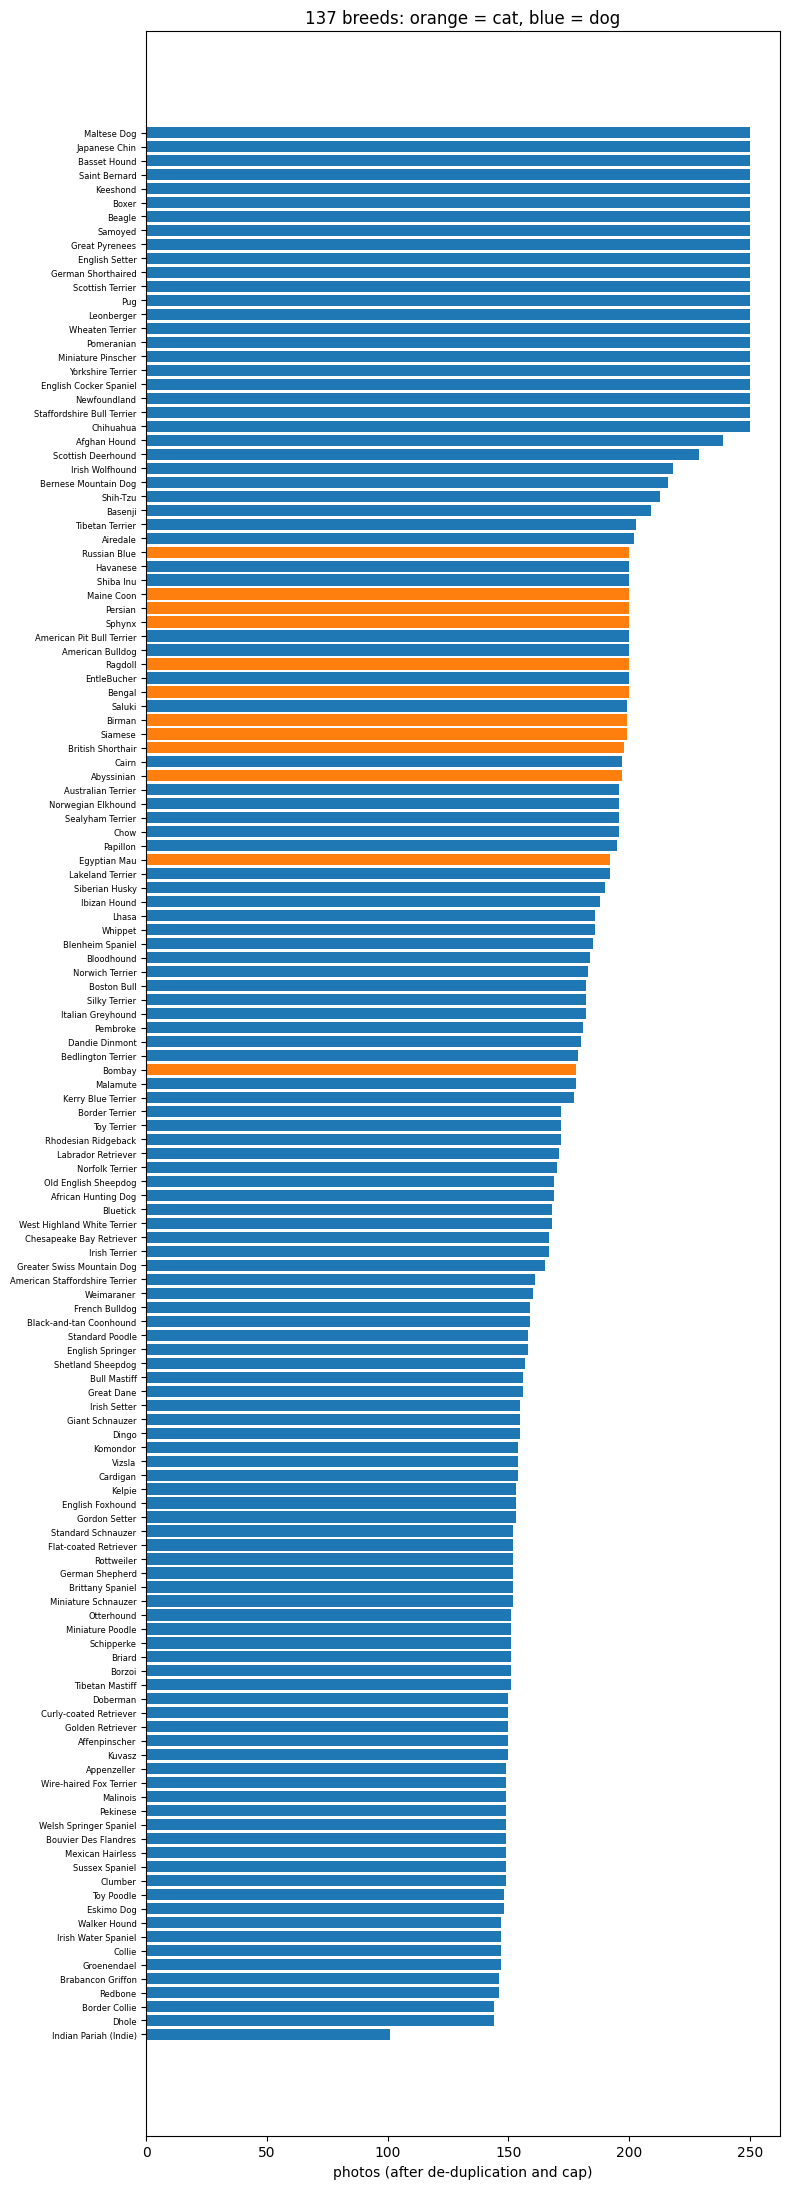

In [14]:
import matplotlib.pyplot as plt

counts = manifest["breed"].value_counts().sort_values()
fig, ax = plt.subplots(figsize=(8, 22))
colors = ["tab:orange" if breed_species[b] == "cat" else "tab:blue" for b in counts.index]
ax.barh(counts.index, counts.values, color=colors)
ax.set_xlabel("photos (after de-duplication and cap)")
ax.set_title(f"{len(counts)} breeds: orange = cat, blue = dog")
ax.tick_params(axis="y", labelsize=6)
plt.tight_layout()
plt.savefig(artifacts_dir / "breed_counts.png", dpi=110)
plt.show()

### Step 7: A data module for v2: `src/data_v2.py`
Same photo preparation as v1 (`get_eval_transform` / `get_train_transform` are reused from `src/data.py`,
so the app's preprocessing doesn't change). The only new part is **reading photos from `manifest.csv`**
instead of torchvision's `OxfordIIITPet` class.

It's a new file, so v1's `src/data.py` is untouched.

In [15]:
%%writefile /content/drive/MyDrive/pet-breed-classifier/src/data_v2.py
from pathlib import Path
import pandas as pd
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from src.data import get_eval_transform, get_train_transform   # same preprocessing as v1


class ManifestDataset(Dataset):
    """Reads (photo, label) pairs from the rows of manifest.csv."""

    def __init__(self, rows, roots, transform):
        self.paths = [Path(roots[s]) / p for s, p in zip(rows["source"], rows["path"])]
        self.labels = rows["label"].tolist()
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert("RGB")   # some photos are greyscale/RGBA/CMYK
        return self.transform(img), self.labels[i]


def load_manifest(artifacts_dir):
    return pd.read_csv(Path(artifacts_dir) / "manifest.csv")


def get_loaders_v2(manifest, roots, batch_size=32, num_workers=2):
    """Returns train, val and test loaders. Only train uses augmentation."""
    def make(split, transform, shuffle):
        rows = manifest[manifest["split"] == split]
        ds = ManifestDataset(rows, roots, transform)
        return DataLoader(ds, batch_size=batch_size, shuffle=shuffle, num_workers=num_workers)

    return (make("train", get_train_transform(), True),
            make("val",   get_eval_transform(),  False),
            make("test",  get_eval_transform(),  False))

Writing /content/drive/MyDrive/pet-breed-classifier/src/data_v2.py


In [16]:
import sys, importlib, torch
sys.path.append(str(project_dir))
import src.data_v2
importlib.reload(src.data_v2)
from src.data_v2 import load_manifest, get_loaders_v2

manifest = load_manifest(artifacts_dir)
train_loader, val_loader, test_loader = get_loaders_v2(manifest, ROOTS)

images, labels = next(iter(train_loader))
print("batch:", images.shape, "| labels:", labels[:8].tolist())
print("train/val/test batches:", len(train_loader), len(val_loader), len(test_loader))

batch: torch.Size([32, 3, 224, 224]) | labels: [50, 71, 10, 69, 3, 128, 123, 85]
train/val/test batches: 552 119 119


In [17]:
# How many photos per breed come from each source (Oxford / Stanford / Indie)
mix = manifest.pivot_table(index="breed", columns="source", values="path", aggfunc="count", fill_value=0)
print(mix.sum())                                   # totals per source
print("\nmerged breeds (Oxford + Stanford):")
print(mix[(mix.get("oxford", 0) > 0) & (mix.get("stanford", 0) > 0)])

source
indie         101
oxford       5947
stanford    19168
dtype: int64

merged breeds (Oxford + Stanford):
source                      indie  oxford  stanford
breed                                              
Basset Hound                    0     128       122
Beagle                          0     126       124
Boxer                           0     142       108
Chihuahua                       0     145       105
English Cocker Spaniel          0     148       102
English Setter                  0     142       108
German Shorthaired              0     144       106
Great Pyrenees                  0     129       121
Japanese Chin                   0     118       132
Keeshond                        0     133       117
Leonberger                      0     117       133
Miniature Pinscher              0     129       121
Newfoundland                    0     123       127
Pomeranian                      0     107       143
Pug                             0     117       133
Saint 

In [18]:
print(manifest.groupby("species")["breed"].nunique()) # breeds per species
print(manifest["species"].value_counts()) # photos per species

species
cat     12
dog    125
Name: breed, dtype: int64
species
dog    22853
cat     2363
Name: count, dtype: int64


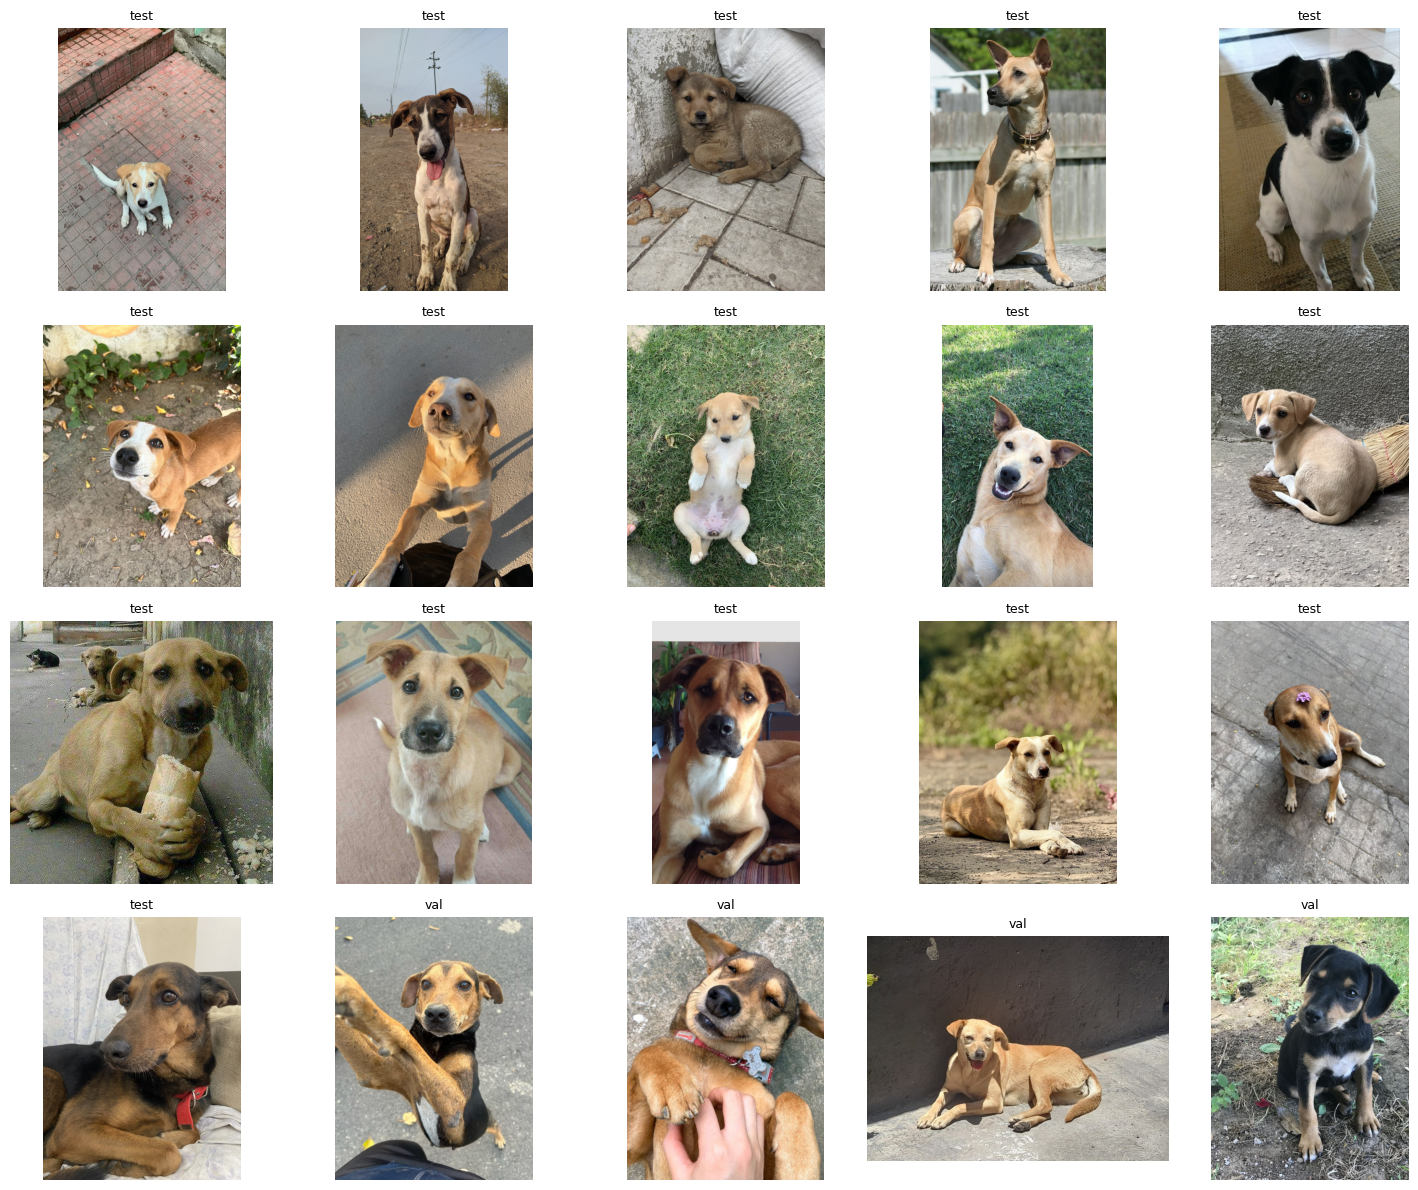

In [20]:
from PIL import Image
import matplotlib.pyplot as plt

indie = manifest[manifest.source == "indie"].sample(20, random_state=seed)
fig, axes = plt.subplots(4, 5, figsize=(15, 12))
for ax, (_, r) in zip(axes.flatten(), indie.iterrows()):
    ax.imshow(Image.open(Path(ROOTS["indie"]) / r["path"]).convert("RGB"))
    ax.set_title(r["split"], fontsize=9)
    ax.axis("off")
plt.tight_layout(); plt.show()

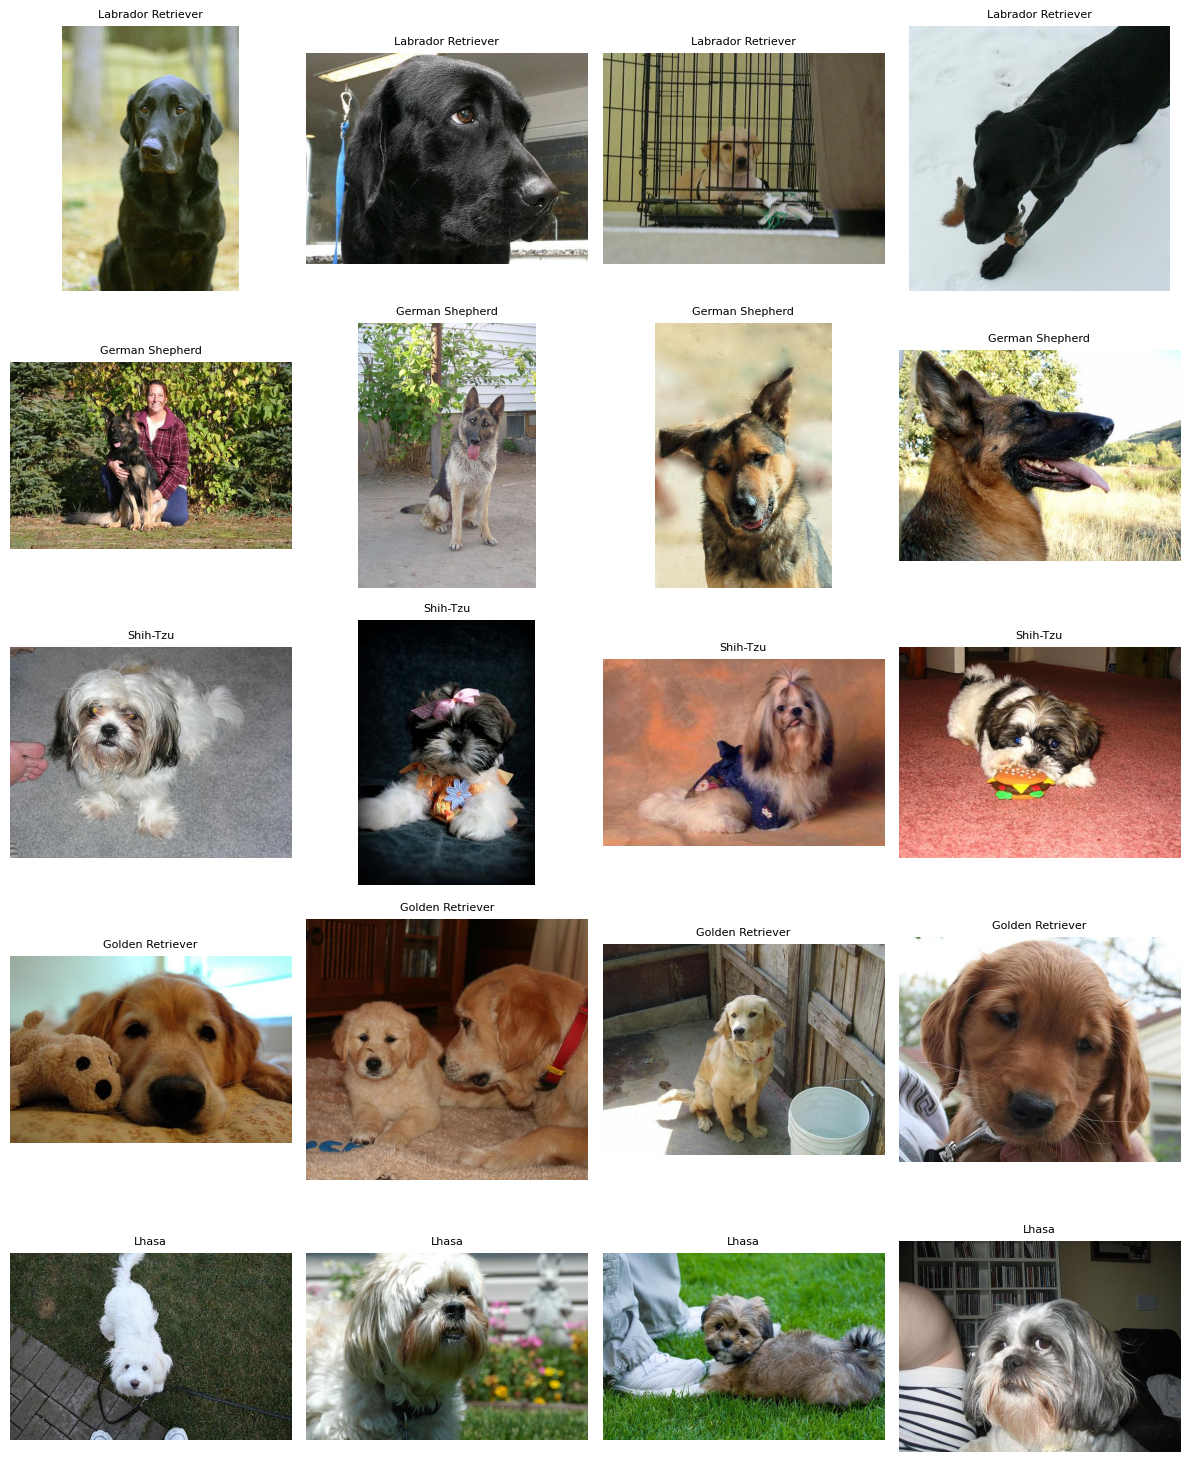

In [21]:
new = ["Labrador Retriever", "German Shepherd", "Shih-Tzu", "Golden Retriever", "Lhasa"]
fig, axes = plt.subplots(len(new), 4, figsize=(12, 3 * len(new)))
for row, breed in zip(axes, new):
    rows = manifest[manifest.breed == breed].sample(4, random_state=seed)
    for ax, (_, r) in zip(row, rows.iterrows()):
        ax.imshow(Image.open(Path(ROOTS[r["source"]]) / r["path"]).convert("RGB"))
        ax.set_title(breed, fontsize=8); ax.axis("off")
plt.tight_layout(); plt.show()